
# Evaluare 01: Învățarea supervizată
Acest test are scopul de a evalua cunoștințele tale despre importul datelor, vizualizarea acestora și utilizarea modelelor de machine learning.
Te rugăm să completezi cerințele direct în celulele dedicate fiecărei secțiuni.


## 1. Importul datelor
1. Importă biblioteca `pandas` și încarcă fișierul `Human_Activity_Recognition_Using_Smartphones_Data.csv`.
2. Verifică dimensiunile și tipurile de date.
3. Afișează primele 5 rânduri din DataFrame și verifică prezența valorilor lipsă.


In [ ]:
import pandas as pd
import numpy as np


df = pd.read_csv("../dataset/Human_Activity_Recognition_Using_Smartphones_Data - Human_Activity_Recognition_Using_Smartphones_Data.csv")


print("Dimensiuni (randuri, coloane):", df.shape)
print("\nTipuri de date:")
print(df.dtypes.value_counts())

# primele randuri
display(df.head())
print("Total valori lipsa:", df.isnull().sum().sum())

# Distributia claselor 
print(df["Activity"].value_counts())

Dimensiuni (rânduri, coloane): (10299, 562)

Tipuri de date:
float64    561
str          1
Name: count, dtype: int64


,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,fBodyBodyGyroJerkMag-skewness(),fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)",Activity
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,-0.923527,-0.934724,...,-0.298676,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627,STANDING
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,-0.957686,-0.943068,...,-0.595051,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317,STANDING
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,-0.977469,-0.938692,...,-0.390748,-0.760104,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118,STANDING
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750,-0.989302,-0.938692,...,-0.117290,-0.482845,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663,STANDING
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672,-0.990441,-0.942469,...,-0.351471,-0.699205,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892,STANDING


Total valori lipsă: 0
Activity
LAYING                1944
STANDING              1906
SITTING               1777
WALKING               1722
WALKING_UPSTAIRS      1544
WALKING_DOWNSTAIRS    1406
Name: count, dtype: int64



## 2. Vizualizare date cu Matplotlib și Seaborn
1. Creează un grafic scatter care să afișeze relația dintre două coloane numeric.
2. Utilizează Seaborn pentru a crea o hartă de căldură (heatmap) a corelațiilor dintre coloane.


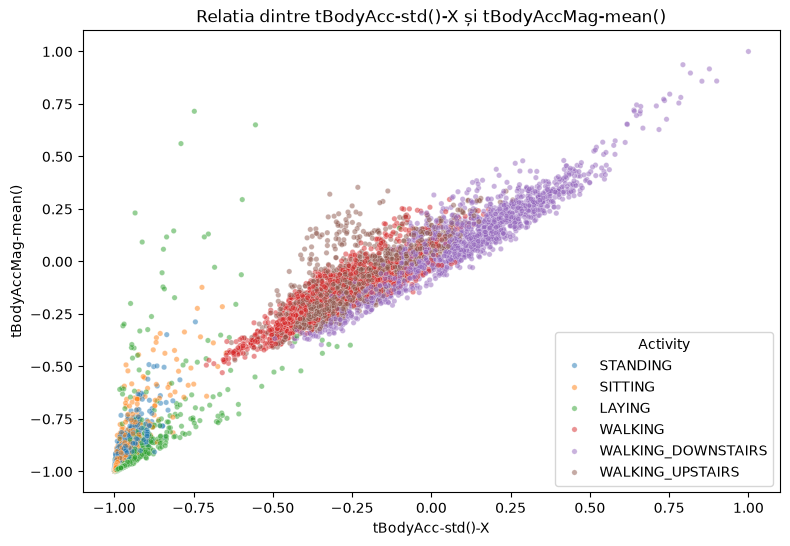

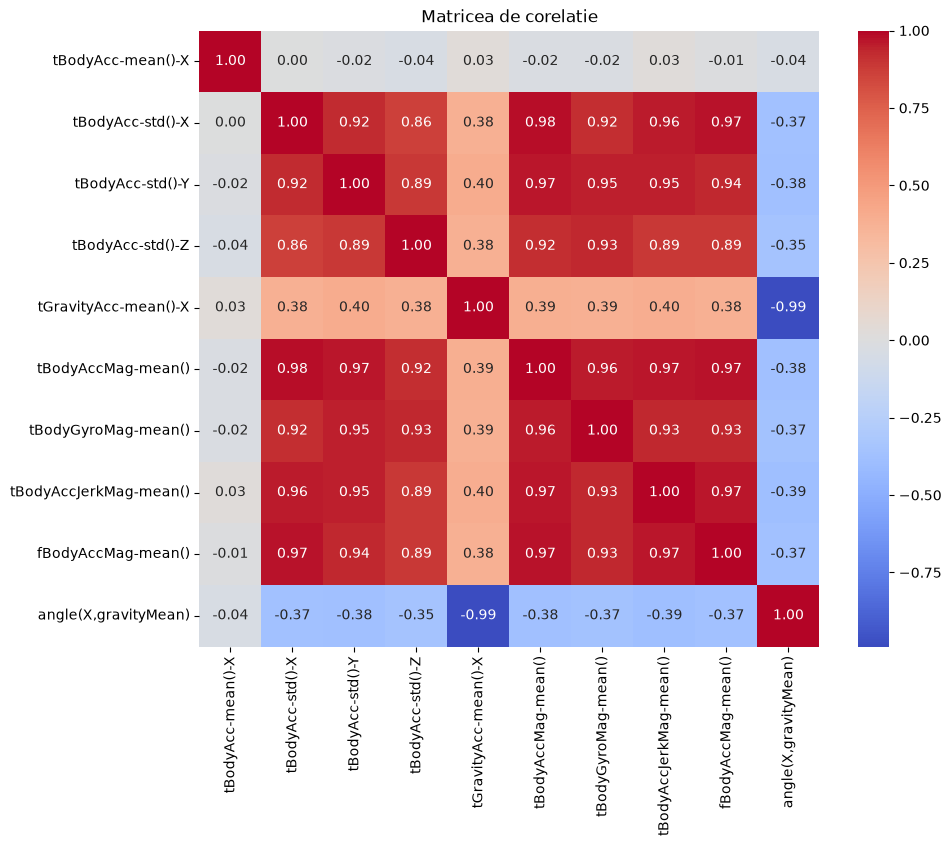

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1 Scatter plot
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x="tBodyAcc-std()-X", y="tBodyAccMag-mean()",
                hue="Activity", alpha=0.5, s=15)
plt.title("Relatia dintre tBodyAcc-std()-X și tBodyAccMag-mean()")
plt.show()

# 2 Heatmap al corelațiilor, datasetul are 500+ coloane, am selectat doar 10 coloane
columns = ["tBodyAcc-mean()-X", "tBodyAcc-std()-X", "tBodyAcc-std()-Y", "tBodyAcc-std()-Z",
           "tGravityAcc-mean()-X", "tBodyAccMag-mean()", "tBodyGyroMag-mean()",
           "tBodyAccJerkMag-mean()", "fBodyAccMag-mean()", "angle(X,gravityMean)"]
plt.figure(figsize=(10, 8))
sns.heatmap(df[columns].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Matricea de corelatie")
plt.show()

## 3. Metrici ale erorii
1. Împarte setul de date în seturi de antrenare și testare (80%-20%).
2. Construiește un model de regresie liniară pe datele numerice.
3. Evaluează performanța modelului utilizând **MAE**, **MSE**, și **RMSE**.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Regresie: prezicem magnitudinea acceleratiei corpului din deviatiile standard pe X, Y, Z
X_reg = df[["tBodyAcc-std()-X", "tBodyAcc-std()-Y", "tBodyAcc-std()-Z"]]
y_reg = df["tBodyAccMag-mean()"]

# Impărtire 80/20 andtrenare/test
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)

# Model de regresie liniara
lin_reg = LinearRegression()
lin_reg.fit(X_train_r, y_train_r)
y_pred_r = lin_reg.predict(X_test_r)

# Metrici ale erorii
mae = mean_absolute_error(y_test_r, y_pred_r)
mse = mean_squared_error(y_test_r, y_pred_r)
rmse = np.sqrt(mse)
print(f"MAE:  {mae:.4f}")
print(f"MSE:  {mse:.4f}")
print(f"RMSE: {rmse:.4f}")

MAE:  0.0162
MSE:  0.0018
RMSE: 0.0421



## 4. Validare încrucișată (Cross Validation)
1. Importă biblioteca `scikit-learn`.
2. Împarte setul de date în seturi de antrenare și testare (80%-20%).
3. Utilizează `cross_val_score` pentru a evalua performanța unui model KNN pe setul de date.


In [ ]:
# Importul scikit-learn
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Clasificare: prezicem activitatea din toate cele 561 de caracteristici
X = df.drop(columns=["Activity"])
y = df["Activity"]

# 2. Impărțire 80/20 antrenare/test 
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 3. cross_val_score cu un model KNN (5 fold-uri pe setul de antrenare)
knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
scoruri = cross_val_score(knn, X_train, y_train, cv=5, scoring="accuracy")
print("Acuratețe pe fiecare fold:", np.round(scoruri, 4))
print(f"Acuratețe medie: {scoruri.mean():.4f} (+/- {scoruri.std():.4f})")

knn.fit(X_train, y_train)
print(f"Acuratețe KNN pe setul de testare: {knn.score(X_test, y_test):.4f}")

Acuratețe pe fiecare fold: [0.9551 0.9563 0.9521 0.9593 0.9514]
Acuratețe medie: 0.9548 (+/- 0.0029)
Acuratețe KNN pe setul de testare: 0.9680



## 5. Modele de Machine Learning
1. **Regresia liniară**: Antrenează un model de regresie liniară și evaluează performanța acestuia pe setul de testare.
2. **Regresia logistică**: Construiește un model logistic pentru o problemă de clasificare binară.
3. **SVM**: Antrenează un model SVM și testează-l pe setul de date.


R^2 pe setul de testare: 0.9919
RMSE pe setul de testare: 0.0421
Coef: {'tBodyAcc-std()-X': np.float64(0.5794), 'tBodyAcc-std()-Y': np.float64(0.2702), 'tBodyAcc-std()-Z': np.float64(0.2263)}
Intercept: 0.0804


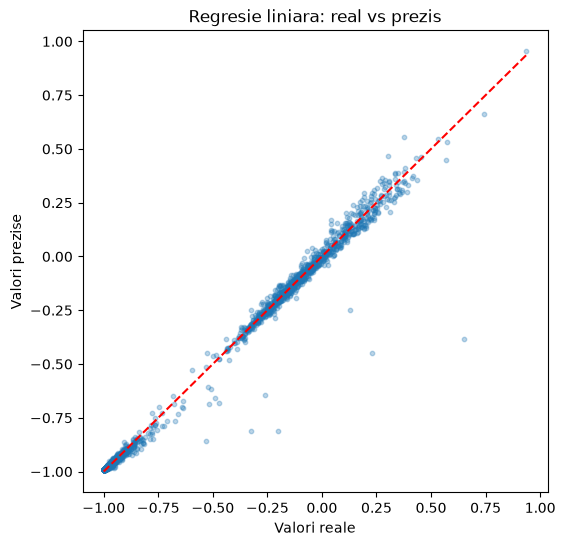

In [15]:
# 5.1 Regresia liniara - evaluare pe setul de testare (folosesc modelul din secțiunea 3)
from sklearn.metrics import r2_score

print(f"R^2 pe setul de testare: {r2_score(y_test_r, y_pred_r):.4f}")
print(f"RMSE pe setul de testare: {rmse:.4f}")
print("Coef:", dict(zip(X_reg.columns, np.round(lin_reg.coef_, 4))))
print(f"Intercept: {lin_reg.intercept_:.4f}")

plt.figure(figsize=(6, 6))
plt.scatter(y_test_r, y_pred_r, alpha=0.3, s=10)
plt.plot([y_test_r.min(), y_test_r.max()], [y_test_r.min(), y_test_r.max()], "r--")
plt.xlabel("Valori reale")
plt.ylabel("Valori prezise")
plt.title("Regresie liniara: real vs prezis")
plt.show()

In [ ]:
# 5.2 Regresia logistica - clasificare binara: activitate în miscare (1) vs. statică (0)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

in_miscare = ["WALKING", "WALKING_UPSTAIRS", "WALKING_DOWNSTAIRS"]
y_bin_train = y_train.isin(in_miscare).astype(int)
y_bin_test = y_test.isin(in_miscare).astype(int)

log_bin = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
log_bin.fit(X_train, y_bin_train)
y_pred_bin = log_bin.predict(X_test)

print(f"Acuratete (binar): {accuracy_score(y_bin_test, y_pred_bin):.4f}")
print(classification_report(y_bin_test, y_pred_bin, target_names=["Static", "In miscare"]))

Acuratețe (binar): 0.9995
              precision    recall  f1-score   support

      Static       1.00      1.00      1.00      1126
  In miscare       1.00      1.00      1.00       934

    accuracy                           1.00      2060
   macro avg       1.00      1.00      1.00      2060
weighted avg       1.00      1.00      1.00      2060



In [ ]:
# 5.3 SVM - clasificare pe toate cele 6 activitati
from sklearn.svm import SVC

svm = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0))
svm.fit(X_train, y_train)
y_pred_svm = svm.predict(X_test)

print(f"Acuratețe SVM: {accuracy_score(y_test, y_pred_svm):.4f}")
print(classification_report(y_test, y_pred_svm))

Acuratețe SVM: 0.9825
                    precision    recall  f1-score   support

            LAYING       1.00      1.00      1.00       389
           SITTING       0.95      0.96      0.96       356
          STANDING       0.97      0.95      0.96       381
           WALKING       1.00      0.99      1.00       344
WALKING_DOWNSTAIRS       0.99      1.00      0.99       281
  WALKING_UPSTAIRS       0.99      1.00      1.00       309

          accuracy                           0.98      2060
         macro avg       0.98      0.98      0.98      2060
      weighted avg       0.98      0.98      0.98      2060



In [ ]:
# Comparatie între modelele de clasificare
rezultate = pd.DataFrame({
    "Model": ["KNN", "Regresie logistică (binar)", "SVM"],
    "Acuratețe": [knn.score(X_test, y_test),
                  accuracy_score(y_bin_test, y_pred_bin),
                  accuracy_score(y_test, y_pred_svm)],
})
rezultate

,Model,Acuratețe
0,KNN,0.967961
1,Regresie logistică (binar),0.999515
2,SVM,0.982524


## 6. Matricea de confuzie
1. Construiește un model de clasificare logistică.
2. Creează matricea de confuzie și afișează-o grafic utilizând Seaborn.

Acuratețe regresie logistică: 0.9859


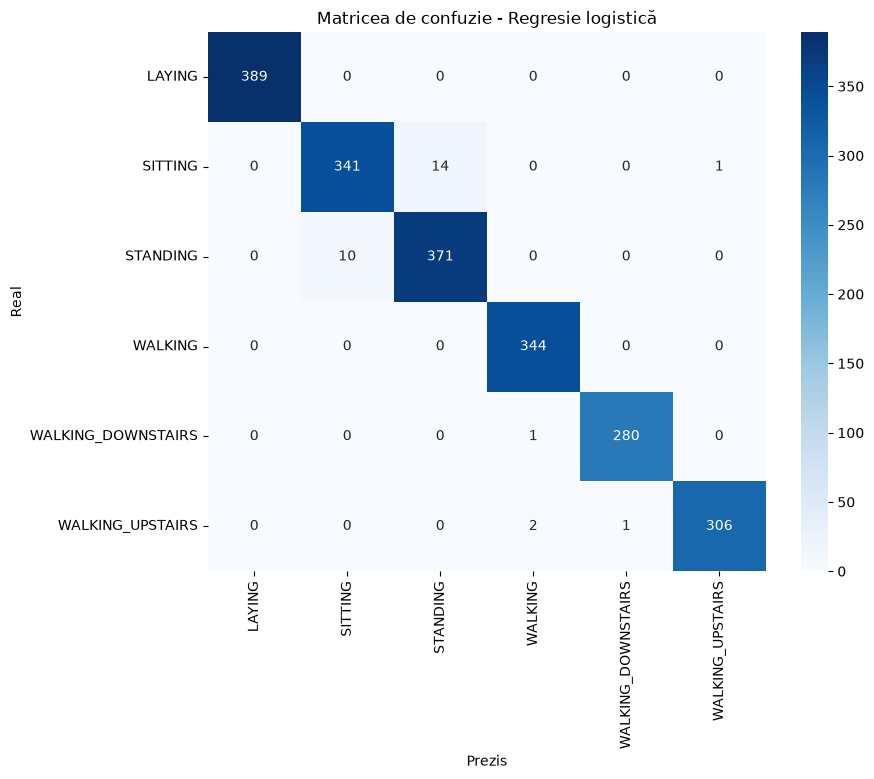

In [ ]:
from sklearn.metrics import confusion_matrix

# Model de clasificare logistica (pe toate cele 6 activități)
log_reg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
log_reg.fit(X_train, y_train)
y_pred_log = log_reg.predict(X_test)
print(f"Acuratete regresie logistica: {accuracy_score(y_test, y_pred_log):.4f}")

# 2. Matricea de confuzie afișată cu Seaborn
etichete = log_reg.classes_
cm = confusion_matrix(y_test, y_pred_log, labels=etichete)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=etichete, yticklabels=etichete)
plt.xlabel("Prezis")
plt.ylabel("Real")
plt.title("Matricea de confuzie - Regresie logistica")
plt.show()


## 7. Gradient Descent
1. Implementați manual algoritmul Gradient Descent pentru a optimiza o funcție cost definită.
2. Utilizați o funcție simplă $$J(\theta) = (\theta x - y)^2 $$ pe un subset al datelor.

Theta gasit prin Gradient Descent: 0.9454
Theta exact (formula analitică):   0.9454
Cost final: 0.015366


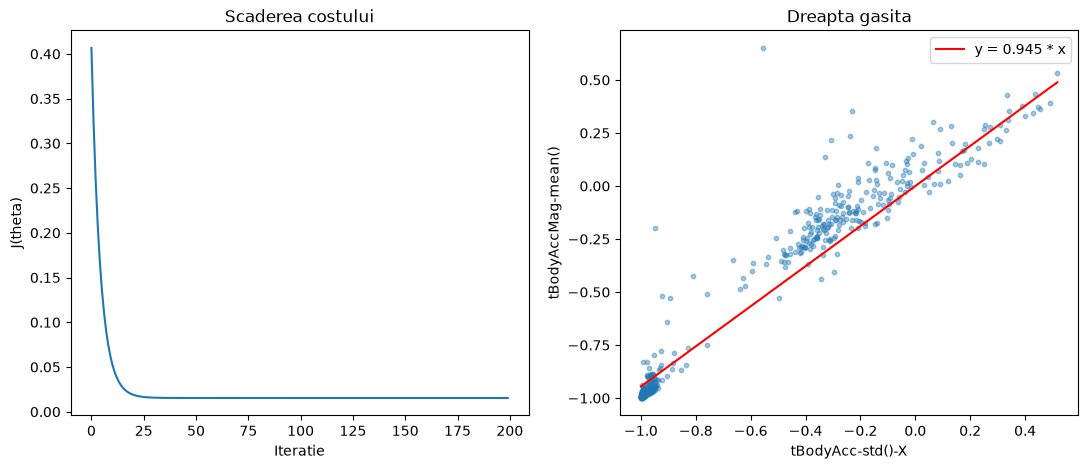

In [ ]:
# Gradient Descent implementat manual pentru J(theta) = (theta * x - y)^2
# Folosim un subset de 500 de randuri x = tBodyAcc-std()-X, y =tBodyAccMag-mean()
subset = df.sample(500, random_state=42)
x_gd = subset["tBodyAcc-std()-X"].values
y_gd = subset["tBodyAccMag-mean()"].values

def cost(theta, x, y):
    # media erorii pătratice pe toate punctele
    return np.mean((theta * x - y) ** 2)

def gradient(theta, x, y):
    # derivata lui (theta*x - y)^2 în raport cu theta este 2*(theta*x - y)*x
    return np.mean(2 * (theta * x - y) * x)

def gradient_descent(x, y, theta=0.0, learning_rate=0.1, iteratii=200):
    istoric = []
    for _ in range(iteratii):
        theta = theta - learning_rate * gradient(theta, x, y)
        istoric.append(cost(theta, x, y))
    return theta, istoric

theta_final, istoric_cost = gradient_descent(x_gd, y_gd)

# Verificare cu solutia exacta: theta* = sum(x*y) / sum(x^2)
theta_exact = np.sum(x_gd * y_gd) / np.sum(x_gd ** 2)
print(f"Theta gasit prin Gradient Descent: {theta_final:.4f}")
print(f"Theta exact (formula analitică):   {theta_exact:.4f}")
print(f"Cost final: {istoric_cost[-1]:.6f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].plot(istoric_cost)
ax[0].set_xlabel("Iteratie")
ax[0].set_ylabel("J(theta)")
ax[0].set_title("Scaderea costului")
ax[1].scatter(x_gd, y_gd, alpha=0.4, s=10)
x_linie = np.linspace(x_gd.min(), x_gd.max(), 100)
ax[1].plot(x_linie, theta_final * x_linie, "r", label=f"y = {theta_final:.3f} * x")
ax[1].set_xlabel("tBodyAcc-std()-X")
ax[1].set_ylabel("tBodyAccMag-mean()")
ax[1].legend()
ax[1].set_title("Dreapta gasita")
plt.show()

## 8. Modele de Machine Learning (part 2 - poate fi omis)
1. **Random Forest**: Utilizează Random Forest pentru a antrena un model și evaluează importanța caracteristicilor.
2. **Boosting și Bagging**: Compară performanța dintre un model AdaBoost și un model Bagging.


Acuratete Random Forest: 0.9806


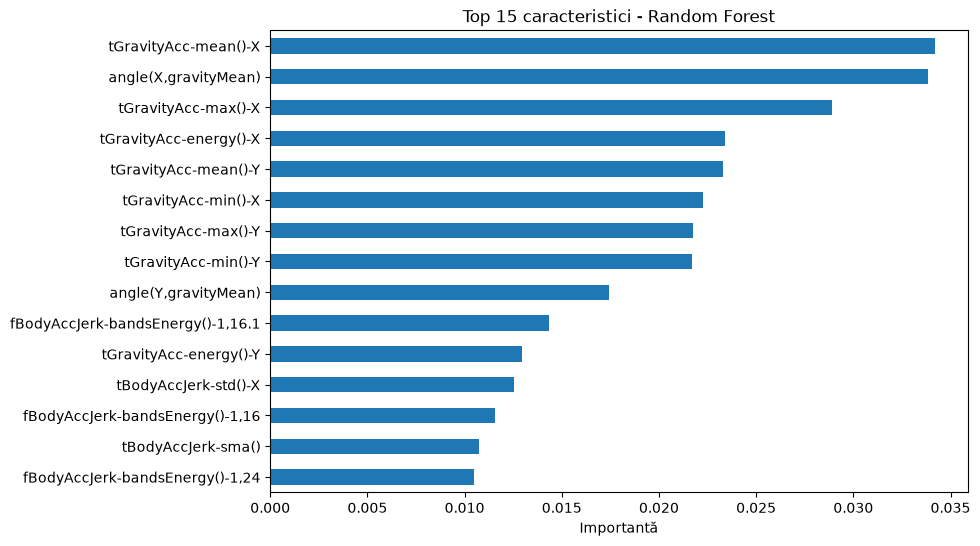

In [ ]:
# 8.1 Random Forest si importanta caracteristicilor
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
print(f"Acuratete Random Forest: {rf.score(X_test, y_test):.4f}")

importante = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
plt.figure(figsize=(9, 6))
importante.head(15).sort_values().plot(kind="barh")
plt.title("Top 15 caracteristici - Random Forest")
plt.xlabel("Importantă")
plt.show()

In [ ]:
# 8.2 Boosting (AdaBoost) vs Bagging ruleaza peste 1.30 min
from sklearn.ensemble import AdaBoostClassifier, BaggingClassifier
from sklearn.tree import DecisionTreeClassifier

ada = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=2), n_estimators=100, random_state=42)
ada.fit(X_train, y_train)

bag = BaggingClassifier(estimator=DecisionTreeClassifier(), n_estimators=50, random_state=42, n_jobs=-1)
bag.fit(X_train, y_train)

print(f"Acuratete AdaBoost: {ada.score(X_test, y_test):.4f}")
print(f"Acuratete Bagging:  {bag.score(X_test, y_test):.4f}")

Acuratețe AdaBoost: 0.9248
Acuratețe Bagging:  0.9650



## 9. Stacking
1. Construiește un model de tip Stacking utilizând Random Forest, SVM și Logistic Regression ca modele de bază.
2. Utilizează un model Logistic Regression ca meta-model.
3. Afișează acuratețea finală pe setul de testare.

In [ ]:
from sklearn.ensemble import StackingClassifier

# Modele de baza: Random Forest, SVM, Logistic Regression
modele_baza = [
    ("rf", RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)),
    ("svm", make_pipeline(StandardScaler(), SVC(kernel="rbf"))),
    ("lr", make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))),
]

# Meta-model: Logistic Regression
stacking = StackingClassifier(estimators=modele_baza,
                              final_estimator=LogisticRegression(max_iter=1000),
                              cv=5, n_jobs=-1)
stacking.fit(X_train, y_train)

# Acuratetea finala pe setul de testare
y_pred_stack = stacking.predict(X_test)
print(f"Acuratete finala Stacking: {accuracy_score(y_test, y_pred_stack):.4f}")

Acuratețe finală Stacking: 0.9927



## Observații
Te rog, să salvezi  și să predai acest notebook după ce ai completat toate secțiunile.
